In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output

sys.path.append('../')


import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [2]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [5]:

config = {
    
    "data": {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_small_v2/labels.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_small/three_images/"
    },

    "hyperparams" :{
        "seed": 424,
        "batch_size": 64,
        "learning_rate": 0.0005,
        "randomize_labels": False,
        "model_type": "multitemporal",
        "backbone": "resnet18",
        "pretrained_backbone" : True,
        "in_channels": 4
    },



    "output": {
        "dir": "trained_models/"
    },

    "wandb": {
        "log_to_wandb" : "True",
        "project" : "project_2",
        "entity" : "janpisl",
        "group": ""
    }
}


In [6]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['train', 'val'], config)
train_dl = dataloaders['train']
val_dl = dataloaders['val']

In [7]:
x,y = next(iter(train_dl))

In [8]:
x.std()

tensor(0.1221)

In [9]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()

In [10]:
train_dataset = train_dl.dataset

In [19]:
train_dataset.img_labels

,geometry,driver,sampleid,split
0,POINT (-6.726781621781269 5.505369307436387),cocoa,3039418,train
1,POINT (-6.113681440369697 5.477072375986622),cocoa,3040124,train
2,POINT (-2.31246031561794 5.533666238886152),cocoa,3038914,train
3,POINT (-7.066344799178449 6.109037178364705),cocoa,3026449,train
4,POINT (-5.811847504905537 6.354277250929334),cocoa,3020208,train
...,...,...,...,...
7528,POINT (101.1252829111954 19.740611461710486),shifting agriculture,5001658,train
7529,POINT (102.49296793126736 20.769004453079134),shifting agriculture,5000585,train
7530,POINT (101.56860150390838 18.316332578738987),shifting agriculture,5002529,train
7531,POINT (102.52126486271712 20.806733695012156),shifting agriculture,5000561,train


In [18]:
import random

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


5002879
shifting agriculture


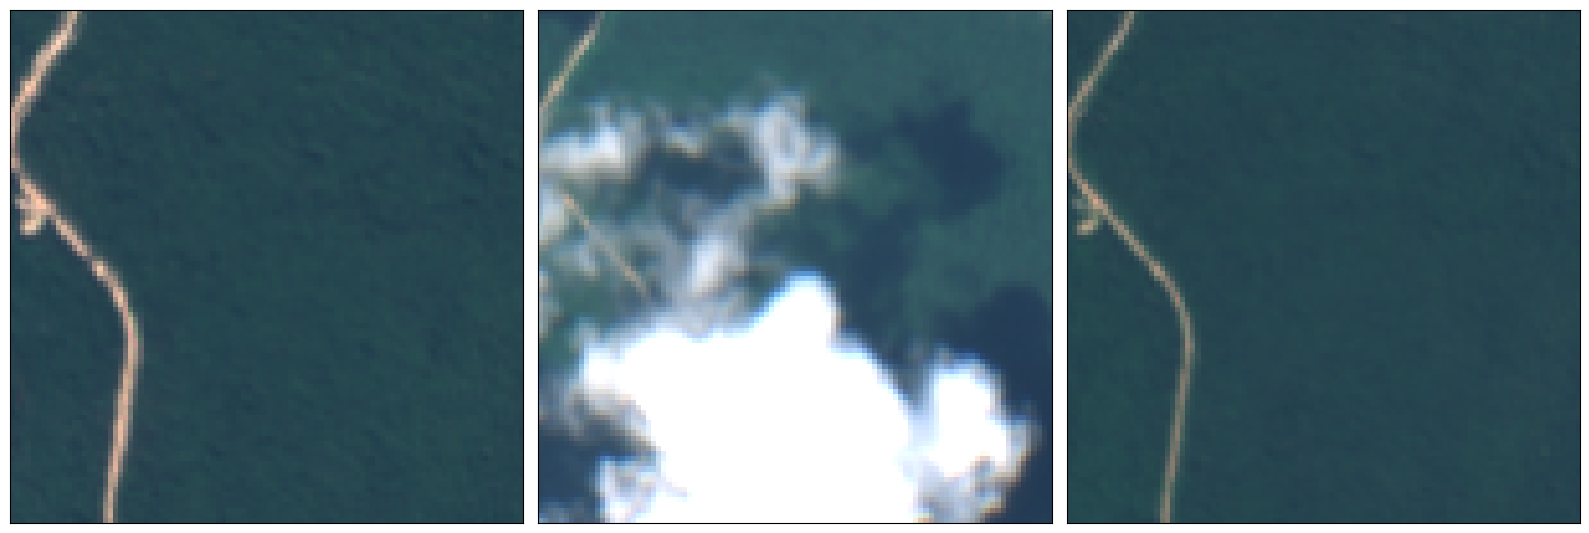

KeyboardInterrupt: Interrupted by user

In [20]:


while True:

    i = random.randint(0,7533)
    if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
        continue
    print(train_dataset.img_labels.iloc[i].sampleid)
    ts, label = train_dataset.__getitem__(i)

    plot_images(ts, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train


## Visualize time series with TMF